---
title: "Itoh Pd membrane reactor: shifting a dehydrogenation equilibrium"
description: "Hydrogen leaves through the wall, so a reaction capped at 18.7 % conversion runs to 99.7 %. The model puts that operating point on its thermodynamic ceiling and lands on the measured number, and the page quantifies how little that comparison can actually test."
categories: [sec:H, struct:S7, tier:T0, data:tier2, phase:gas-solid]
date: 2026-07-31
---

# Itoh Pd membrane reactor: shifting a dehydrogenation equilibrium

**Catalog ID:** `H1.4` · **Structures:** `S7` (two coupled 1-D domains) · **Tier:** T0

At 473 K and 1 atm, cyclohexane diluted in argon dehydrogenates to an
equilibrium conversion of **18.7 %**, and no catalyst, however good, can do
better in an ordinary tube. Itoh packed the catalyst inside a palladium tube
instead. Palladium passes hydrogen and *nothing else*, so the product hydrogen
leaves through the wall as fast as it forms, the reverse reaction is starved,
and the measured conversion reaches **99.7 %**.

This page builds the paper's model with nothing fitted and lands on that
number. It is equally careful about what the comparison can establish: at the
measured operating point the model sits **exactly on its own thermodynamic
ceiling**, so the agreement tests the equilibrium-plus-permeation description
and is insensitive to the kinetics and to the permeation constant. The
sensitivity sweep that shows this is printed in the validation section, and
the summary lines on this page are written to match it.

Two printed statements in the 3-page communication cannot be right as they
stand, and both are corrected below using only other printed statements of the
same paper. A third value that a reader might suspect, the headline purge
rate, turns out to be printed correctly, and is *confirmed* here rather than
corrected.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "H1.4-itoh-membrane-dehydrogenation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import warnings
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt
from pymrm import continuation, newton
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (ItohCase, MembraneReactor, ceiling, conversion_ivp, kp_of_xeq,
                   unconverted_at_equilibrium, xeq_of_kp, root_log)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

## Background

A reversible reaction stops at equilibrium; removing a product moves the
equilibrium. Raymont (1975) proposed exploiting this for H₂S decomposition, and
Kameyama et al. (1981) tried it with a porous Vycor glass membrane, but a
porous membrane passes *everything* to some degree, and Itoh's own simulations
(1984, 1985) showed that leakage of the feed caps what such a reactor can do.

A dense palladium membrane has no such cap. Hydrogen dissolves in the metal
(dissociatively, hence the square-root pressure law), diffuses through, and
recombines on the far side; cyclohexane and benzene cannot cross at all. The
1987 communication is the experimental demonstration: a double-tube reactor,
0.5 wt.% Pt/Al₂O₃ pellets packed inside a 200 µm palladium tube, cyclohexane in
argon fed through the bed, and an argon purge sweeping the shell side to carry
the permeated hydrogen away. Neither cyclohexane nor benzene was detected on
the shell side: the selectivity really is absolute.

The model reaction:

$$
\mathrm{C_6H_{12}} \;\rightleftharpoons\; \mathrm{C_6H_6} + 3\,\mathrm{H_2},
\qquad K_p = \frac{p_B\,p_H^3}{p_C} .
$$

## The published model

Isothermal, isobaric plug flow on both sides, co-current, with molar flow rates
as the variables: $u_i$ on the reaction side, $v_i$ on the shell side, against
dimensionless length $L$. Hydrogen permeation obeys the half-power (Sieverts)
law, Eq. 1:

$$
Q_H = \alpha_H\left(\sqrt{p_H/P_0} - \sqrt{p'_H/P_0}\right),
\qquad
\alpha_H = \frac{2\pi l_0}{\ln(r_o/r_i)}\,D\,C_0 ,
$$

and the species balances (Eqs. 2 and 3) are

$$
\frac{du_C}{dL} = r_C V_r, \qquad
\frac{du_H}{dL} = -3\,r_C V_r
  - \alpha_H\!\left(\sqrt{\tfrac{u_H}{\sum u_i}} - \sqrt{\tfrac{v_H}{\sum v_i}}\right),
$$

(the square roots are of mole fractions because $P_{T_r} = P_{T_s} = P_0$ =
1 atm), with benzene and shell hydrogen closed algebraically (Eqs. 4 and 5),
argon constant on both sides (Eq. 6), and the Langmuir-Hinshelwood rate of
Itoh et al. (1985), Eq. 7:

$$
r_C = \frac{-k\,(K_p\,p_C/p_H^3 - p_B)}{1 + K_B K_p\,p_C/p_H^3},
\qquad
\begin{aligned}
k   &= 0.221\,e^{-4270/T} &&\mathrm{mol\,m^{-3}\,Pa^{-1}\,s^{-1}}\\
K_B &= 2.03\times10^{-10}\,e^{6270/T} &&\mathrm{Pa^{-1}}
\end{aligned}
$$

Inlet conditions (Eq. 8): everything enters at $L=0$; $u_B = u_H = v_H = 0$
there. The authors integrated Eqs. 2 to 7 by Runge-Kutta-Gill.

### Two misprints, and one printed value confirmed

**How the paper was read.** The PDF's page images are 300 dpi bilevel CCITT
scans (`pdfimages -list`), so rendering at 600 dpi is a 2× upsample that
carries no extra information. Every marginal glyph quoted below was therefore
read on the *native* bitmap; the crops are kept with the case file.

Two printed statements cannot be right as they stand. Each is resolved **using
only other printed statements of the same paper**: nothing is fitted and
nothing is guessed.

**Misprint 1: Eq. 5's sign.** The paper prints
$v_H = u_H - 3(u_C^0 - u_C)$. Integrating the paper's own Eqs. 2 and 3 together
with $dv_H/dL = Q_H$ gives the hydrogen balance
$u_H + v_H = 3(u_C^0 - u_C)$; substituting that into the printed Eq. 5 gives
$v_H = -v_H$, so **the printed equation forces $v_H \equiv 0$**, no hydrogen
in the permeate at all, which contradicts the permeation term of Eq. 3 outright.
The correct form is $v_H = 3(u_C^0 - u_C) - u_H$: a sign flip in print.

There is no sign-convention escape. Eq. 8 places *every* initial condition at
$L = 0$ ($u_H = 0$, $v_H = 0$ and $v_A = v_A^0$ there); Figure 3 draws $v_A^0$
entering the separation side at the left, alongside $u_C^0$ and $u_A^0$;
Figure 1 shows the purge gas entering at the feed end and leaving with the
product; and the sentence below Eq. 6 defines $u_i$ and $v_i$ as "the flow rates
of component $i$ in the reaction and separation sides", i.e. positive in $+L$.
The reactor is co-current in the apparatus, in the flow model and in the initial
conditions, so $v_H \geq 0$ throughout. Nothing computed here depends on the
call: the notebook integrates $dv_H/dL = +Q_H$ and uses the corrected identity
only as a check.

**Misprint 2: the equilibrium constant.** The printed
$K_P = 4.89\times10^{35}\,e^{+3190/T}$ Pa³ gives $4.2\times10^{38}$ Pa³ at
473 K. Fed into Eq. 7's own equilibrium condition $K_p\,p_C/p_H^3 = p_B$, that
predicts essentially **complete** equilibrium conversion (an unconverted
fraction of 1e-25), contradicting the paper's stated 18.7 %, the printed
"Equilibrium conversion (0.187)" intercept on Figure 4, and the premise of the
entire study. Two independent checks show this is not a reading error on our
side:

* **A units error cannot explain it, in either direction.** Eq. 7 forces
  $[K_p] = \mathrm{Pa^3}$ ($K_p p_C/p_H^3$ is compared with $p_B$, and
  $K_B K_p p_C/p_H^3$ must be dimensionless given the printed
  $[K_B] = \mathrm{Pa^{-1}}$). Reading the printed number as atm³ instead makes
  it $1.04\times10^{15}$ times *larger* in Pa³ (table below); and expressed in
  atm³ the printed value is $4\times10^{23}$ atm³ against the
  $2.3\times10^{-4}$ atm³ the paper's own $x_{eq}$ requires, 27 orders out
  whichever way the conversion is applied.
* **The sign of the exponent is independently wrong.** Cyclohexane
  dehydrogenation is endothermic ($\Delta H^\circ \approx +206$ kJ/mol from the
  standard formation data used below), so $K_p$ must *rise* with temperature and
  the exponential argument must be negative. The printed $+3190/T$ describes an
  exothermic reaction.

The decision table below evaluates the printed expression and its candidate
repairs against the paper's own $x_{eq}$; none reproduces it. So
$K_p(473\,\mathrm{K})$ is **reconstructed from the stated equilibrium
conversion**: $x_{eq} = 0.187$ at $y_C^0 = 0.197$, 1 atm, all printed numbers.
The model runs at a single temperature, so the Arrhenius form is never needed.

**Confirmed, not corrected: the headline purge rate $v_A^0$.** The text prints
$v_A^0 = 11.8\times10^{-5}$ mol/s, and on the native bitmap that superscript
reads $-5$ cleanly (the same line carries an unambiguous $-7$ for comparison).
**This page therefore does not correct the paper here**; it confirms the printed
value, because everything else on the page would change if the exponent were
$-6$, and the confirmation happens to be available without any kinetics: with
$v_A^0 = 11.8\times10^{-6}$ mol/s, *no* kinetics and *no* permeance, both taken
infinitely fast, could push conversion past $X \approx 0.72$, so the measured
0.997 rules that reading out (numbers below). That ceiling is specific to the
**co-current** arrangement (a counter-current purge of the same size would do
much better), which is exactly why the three independent statements of
co-currency quoted above matter. What *is* illegible on the scan is Figure 4's
hand-lettered abscissa exponent ($v_A^0 \times 10^5$ or $10^6$); consistency
with the text makes it $\times 10^5$, and nothing on this page depends on
reading it.

**Deviation convention, used everywhere on this page:**
(model − measured)/measured.

## Parameters and assumptions

| Quantity | Value | Source |
|---|---|---|
| $T$ | 473 K | stated (data file) |
| $P_{T_r} = P_{T_s} = P_0$ | 1.013 × 10⁵ Pa | stated, isobaric and atmospheric (data file) |
| Feed | 19.7 mol% cyclohexane in argon | stated (data file) |
| Tube | $r_i$ = 8.5 mm, $r_o$ = 8.7 mm, $l_0$ = 0.14 m | Figure 1 and the $\alpha_H$ identity (below) |
| $D$ (H in Pd) | 9.23 × 10⁻¹⁰ m²/s | stated (Nagamoto and Inoue) |
| $C_0$ | 1280 mol/m³ | stated (Sieverts and Danz) |
| $\alpha_H$ | 4.47 × 10⁻⁵ mol/s | stated; recomputed to -0.03 % below |
| $k(473)$ | 2.653 × 10⁻⁵ mol m⁻³ Pa⁻¹ s⁻¹ | Eq. 7 |
| $K_B(473)$ | 1.160 × 10⁻⁴ Pa⁻¹ | Eq. 7 |
| $K_p(473)$ | 2.357 × 10¹¹ Pa³ | reconstructed from $x_{eq}=0.187$ (misprint 2) |
| $V_r$ | $\pi r_i^2 l_0$ = 3.18 × 10⁻⁵ m³ | "gross volume of the reaction section" |

**Note on the radii, and how little it matters.** The text says "17.0 mm OD",
but recomputing $\alpha_H$ from Eq. 1 reproduces the printed
4.47 × 10⁻⁵ mol/s only with $r_i$ = 8.5 mm, $r_o$ = 8.7 mm (-0.03 %; the OD
reading gives -2.4 %). Strictly, that identity shows what Itoh *substituted into
Eq. 1*, not what the tube physically was: "17.0 mm OD" may simply have been
mis-stated, or $\alpha_H$ computed with the wrong radii. Either way the model
uses the *printed* $\alpha_H$, and the only quantity that consumes $r_i$ is
$V_r$ (4.9 % between the two readings). $V_r$ enters the balances only as the
product $k\,V_r$, so the ×0.1 to ×10 variation of $k$ in the sensitivity sweep
below covers it many times over, and that sweep moves the headline conversion
by less than 1e-8. The identity is recorded because it is a genuine internal
check on Eq. 1, not because anything hangs on it.

**Assumptions inherited from the paper:** isothermal, isobaric, plug flow on
both sides, negligible reaction on the palladium surface itself, Sieverts-law
permeation, and no mass-transfer resistance between bed and wall.

In [3]:
# Printed in the paper (every character verified on the native 300 dpi bitmap).
# The operating conditions (T, P0, feed, flows) are rows of the data file below.
L0 = 0.14                        # m, tube length (Figure 1)
RI, RO = 8.5e-3, 8.7e-3          # m, tube radii (selected by the alpha_H identity)
RI_OD, RO_OD = 8.3e-3, 8.5e-3    # m, the radii if "17.0 mm" is the outer diameter
D_PD = 9.23e-10                  # m2/s, H in Pd (Nagamoto and Inoue)
C_0 = 1280.0                     # mol/m3, Sieverts reference concentration
ALPHA_H = 4.47e-5                # mol/s, printed permeation constant (Eq. 1)
UC0_CURVES = np.array([0.29e-6, 0.80e-6, 1.64e-6])   # mol/s, Figure 4 legend labels
UC0_MID, VA0_MID = UC0_CURVES[1], 3e-5                # mid-map operating point (chosen)


def alpha_h(r_i=RI, r_o=RO):
    """Eq. 1's permeation constant from its own printed inputs (mol/s)."""
    return 2 * np.pi * L0 * D_PD * C_0 / np.log(r_o / r_i)

## The data

A 3-page communication with no tables: the validation targets live in the
running text. The one **measurement** is the headline conversion, 0.997, at
$u_C^0 = 2.90\times10^{-7}$ mol/s and $v_A^0 = 11.8\times10^{-5}$ mol/s; the
one **thermodynamic statement** is the equilibrium conversion, 0.187, for the
same feed without a membrane.

The measured conversion is quoted to three digits with no stated uncertainty,
so it means $X \in [0.9965, 0.9975]$ at best, which already bounds how finely
any deviation from it can be quoted. The validation section works that through.

Figure 4 also carries experimental markers at other purge rates. They are *not*
digitised here: the ranked-validation policy of this gallery takes a stated
numerical result over a digitised figure, and the stated result plus two
internal identities (below) close the model without any figure work.

In [4]:
vals = load_data("itoh-1987-stated-values.csv", page=PAGE)
meta = load_meta("itoh-1987-stated-values.csv", page=PAGE)
print(vals.to_string(index=False, columns=["quantity", "value", "unit", "kind"]))
print(f"\n{cite_data(meta)}")


def stated(offset=0):
    """The stated values by name. ``offset`` reads each value that many rows
    further down the file (a break-row handle: a misaligned read)."""
    v = vals.value.to_numpy(dtype=float)
    return {q: v[(i + offset) % len(v)] for i, q in enumerate(vals.quantity)}


S = stated()
X_MEASURED = S["measured_conversion"]
X_EQ_STATED = S["equilibrium_conversion"]
UC0, VA0 = S["u_C0"], S["v_A0"]
T, P0, Y_C0 = S["temperature"], S["pressure"], S["feed_cyclohexane_fraction"]
VA0_E6 = VA0 / 10.0              # the same digits read with the exponent -6
X_BAND = (X_MEASURED - 0.0005, X_MEASURED + 0.0005)   # three printed digits

                 quantity        value  unit                    kind
      measured_conversion 9.970000e-01     -             measurement
                     u_C0 2.900000e-07 mol/s     operating condition
                     v_A0 1.180000e-04 mol/s     operating condition
   equilibrium_conversion 1.870000e-01     - thermodynamic statement
feed_cyclohexane_fraction 1.970000e-01     -     operating condition
              temperature 4.730000e+02     K     operating condition
                 pressure 1.013000e+05    Pa     operating condition

Itoh, N. (1987) — AIChE Journal 33(9) 1576-1578 — doi:10.1002/aic.690330921 — stated in text


### Reconstructing the equilibrium constant from the stated equilibrium conversion

For the feed (1 mol C, $n_{Ar} = (1-y_C^0)/y_C^0$ mol Ar) at conversion $x$
and total pressure $P_0$, Eq. 7's equilibrium condition
$K_p p_C/p_H^3 = p_B$ rearranges to

$$
K_p(x) \;=\; \frac{27\,x^4\,P_0^3}{(1-x)\,\bigl(1 + n_{Ar} + 3x\bigr)^3},
$$

so the printed $x_{eq} = 0.187$ fixes $K_p$ at the one temperature the model
needs. $K_p(x)$ increases strictly on $0 < x < 1$, so its inverse is a single
root, found in the logarithm of the unconverted fraction $1 - x$ so that a
conversion within 1e-16 of complete is still resolved. The decision table then
evaluates the printed expression and its possible repairs against the paper's
own statement, and a van 't Hoff estimate from standard formation enthalpies
and entropies (NIST WebBook values, constant-$\Delta H$ approximation) checks
the reconstruction's magnitude independently.

The table also localises the corruption. The printed *prefactor* is of the
right thermodynamic family, $\exp(\Delta S^\circ/R) = 9.0\times10^{33}$ Pa³
against the printed $4.89\times10^{35}$, a factor 54, whereas the printed
*argument* is wrong in sign and by 27 orders of magnitude. Repairing only the
argument, i.e. asking what slope makes the printed prefactor reproduce the
paper's own $x_{eq}$, gives $-26{,}484$ K, within 7 % of the van 't Hoff slope
$-\Delta H^\circ/R = -24{,}814$ K. That is the most economical diagnosis: one
number was mangled in typesetting, and repairing only that number reproduces
both the paper's own equilibrium conversion and standard thermodynamics. It is
a diagnosis, not a source: the page uses the reconstruction from $x_{eq}$,
which needs no such reasoning.

In [5]:
R_GAS = 8.314                    # J/(mol K)
# NIST WebBook standard formation data at 298.15 K (an independent magnitude check):
DHF_BENZENE, DHF_CYCLOHEXANE = 82.9, -123.4          # kJ/mol
S_BENZENE, S_CYCLOHEXANE, S_H2 = 269.2, 298.35, 130.68   # J/(mol K)
KP_PRINTED_PREFACTOR, KP_PRINTED_ARGUMENT = 4.89e35, 3190.0   # the printed K_P line


def thermo(T=T, P0=P0, y_C0=Y_C0, x_eq=X_EQ_STATED, p_std=1e5, dhf_benzene=DHF_BENZENE):
    """Every closed-form number of this section. The arguments are break-row handles."""
    K_p = kp_of_xeq(x_eq, y_C0, P0)
    dH = (dhf_benzene - DHF_CYCLOHEXANE) * 1e3                 # J/mol
    dS = S_BENZENE + 3 * S_H2 - S_CYCLOHEXANE                  # J/(mol K)
    lnK = -(dH - 298.15 * dS) / (R_GAS * 298.15) + dH / R_GAS * (1 / 298.15 - 1 / T)
    K_vh = np.exp(lnK) * p_std ** 3                            # Pa^3 (p_std reference)
    printed = KP_PRINTED_PREFACTOR * np.exp(KP_PRINTED_ARGUMENT / T)
    slope_repair = T * np.log(K_p / KP_PRINTED_PREFACTOR)
    slope_vh = -dH / R_GAS
    prefac_vh = np.exp(dS / R_GAS) * p_std ** 3
    return dict(K_p=K_p, K_vh=K_vh, ratio=K_p / K_vh, dH_kJ=dH / 1e3, printed=printed,
                printed_unconverted=unconverted_at_equilibrium(printed, y_C0, P0),
                atm3_factor=P0 ** 3, printed_atm3=printed / P0 ** 3, needed_atm3=K_p / P0 ** 3,
                orders=np.log10(printed / K_p), slope_repair=slope_repair, slope_vh=slope_vh,
                slope_gap_pct=abs(slope_repair - slope_vh) / abs(slope_vh) * 100,
                prefac_vh=prefac_vh, prefac_ratio=KP_PRINTED_PREFACTOR / prefac_vh)


TH = thermo()
K_P, K_P_VH = TH["K_p"], TH["K_vh"]
print(f"K_p(473) reconstructed from x_eq = {X_EQ_STATED}: {K_P:.4e} Pa^3")
print(f"K_p(473) van 't Hoff estimate (independent):  {K_P_VH:.2e} Pa^3 "
      f"(ratio {TH['ratio']:.2f}, consistent for a constant-dH estimate)")
print(f"standard reaction enthalpy from the same data: dH298 = {TH['dH_kJ']:+.1f} kJ/mol")
print("  -> endothermic, so K_p must RISE with T: the exponential argument must")
print("     be negative, and the printed +3190/T cannot be right on its own.\n")
rows = [("printed: 4.89e35 exp(+3190/T)", TH["printed"]),
        ("printed value read as atm^3, not Pa^3", TH["printed"] * P0 ** 3),
        ("sign repair: 4.89e35 exp(-3190/T)",
         KP_PRINTED_PREFACTOR * np.exp(-KP_PRINTED_ARGUMENT / T)),
        ("digit repair: 4.89e3 exp(+3190/T)", 4.89e3 * np.exp(KP_PRINTED_ARGUMENT / T)),
        (f"argument repair: 4.89e35 exp({TH['slope_repair']:.0f}/T)",
         KP_PRINTED_PREFACTOR * np.exp(TH["slope_repair"] / T)),
        ("reconstructed from x_eq (this page)", K_P)]
table = ["decision table: each K_P candidate against the paper's own x_eq = 0.187",
         f"  {'candidate':<40}{'K_p(473) [Pa^3]':>17}{'1 - x_eq':>11}{'x_eq':>8}"]
for label, kp in rows:
    y = unconverted_at_equilibrium(kp, Y_C0, P0)
    table.append(f"  {label:<40}{kp:>17.3e}{y:>11.2e}{1 - y:>8.3f}")
print("\n".join(table))
print(f"  -> the printed expression, a units re-reading, a sign flip and a digit\n"
      f"     drop all fail against the paper's own 18.7 %. Only repairing the\n"
      f"     exponential ARGUMENT works, and the slope it needs, "
      f"{TH['slope_repair']:.0f} K, is within\n"
      f"     {TH['slope_gap_pct']:.0f} % of the van 't Hoff slope -dH/R = "
      f"{TH['slope_vh']:.0f} K, while the printed prefactor\n"
      f"     is within a factor {TH['prefac_ratio']:.0f} of exp(dS/R) = "
      f"{TH['prefac_vh']:.2e} Pa^3.\n"
      f"     Printed value in atm^3: {TH['printed_atm3']:.1e}; required: "
      f"{TH['needed_atm3']:.1e} atm^3 ({TH['orders']:.1f} decades apart).\n"
      "     Diagnosis only: the page uses the reconstruction from x_eq, which\n"
      "     assumes nothing about where the printed line came from.")
CASE = ItohCase.printed(T, P0, Y_C0, K_P, alpha_H=ALPHA_H, r_i=RI, l_0=L0)

K_p(473) reconstructed from x_eq = 0.187: 2.3566e+11 Pa^3
K_p(473) van 't Hoff estimate (independent):  1.49e+11 Pa^3 (ratio 1.58, consistent for a constant-dH estimate)
standard reaction enthalpy from the same data: dH298 = +206.3 kJ/mol
  -> endothermic, so K_p must RISE with T: the exponential argument must
     be negative, and the printed +3190/T cannot be right on its own.

decision table: each K_P candidate against the paper's own x_eq = 0.187
  candidate                                 K_p(473) [Pa^3]   1 - x_eq    x_eq
  printed: 4.89e35 exp(+3190/T)                   4.152e+38   1.28e-25   1.000
  printed value read as atm^3, not Pa^3           4.316e+53   1.23e-40   1.000
  sign repair: 4.89e35 exp(-3190/T)               5.759e+32   9.25e-20   1.000
  digit repair: 4.89e3 exp(+3190/T)               4.152e+06   9.88e-01   0.012
  argument repair: 4.89e35 exp(-26484/T)          2.357e+11   8.13e-01   0.187
  reconstructed from x_eq (this page)             2.357e+11   8.13e-01 

## PyMRM implementation

The two channels are one steady convection-reaction system on $L \in [0,1]$,
scaled by the feed, $w = (u_C, u_H, v_H)/u_C^0$, so every unknown is of order
one. The state is `(n_z, 3)`: the reaction-side fields $(u_C, u_H)$ and the
shell-side $v_H$ are two domains of a `pymrm.BlockLayout`, concatenated along
the field axis (`"tube"` `(n_z, 2)`, `"shell"` `(n_z, 1)`). Each channel gets
its own `construct_convflux_upwind` with velocity $\pm 1$ (the balances are
already in flow-rate form) and `construct_div` with `nu=0` ($L$ is Cartesian),
assembled once and placed with `layout.place`; benzene and both argon flows are
algebraic. The channels couple only through the pointwise source, linearised by
`NumJac` on the full state, which couples the last axis in full.

Boundary conditions use the **outward normal** ($a\,\partial w/\partial n +
b\,w = d$). At each inlet the condition is Dirichlet ($a{=}0, b{=}1$): tube
$(u_C, u_H) = (1, 0)$, shell $v_H = 0$. A convection-only channel needs no
outlet condition, and the library's `{"outflow": True}` imposes none: the exit
face carries the last cell's value, so the scheme is exact backward Euler in
$L$ and every balance closes on the faces. Outlet values are read with
`compute_boundary_values`, never from a cell centre.

Three numerical points:

- **Scale the unknowns to order one.** `NumJac` perturbs every unknown by at
  least an absolute 10⁻⁶; flows of order 10⁻⁷ mol/s would be perturbed by more
  than their own value and the Jacobian would be noise.
- **Regularise Eq. 7 algebraically, not with branches.** Multiplying through
  by $p_H^3$ gives $r_C = -k\,(K_p p_C - p_B\,p_H^3)/(p_H^3 + K_B K_p p_C)$,
  which is smooth at the $p_H \to 0$ inlet (limit $-k/K_B$: the reaction is
  zero-order when far from equilibrium) instead of the printed form's 0·∞.
- **`pymrm.newton` with `damping="monotone"` and a lower bound of 0.** Near
  complete conversion the solution rides an equilibrium plateau where the rate
  switches from zero order to equilibrium-pinned over a narrow range of $p_H$;
  the monotonicity test carries the iteration over it. The bound keeps $u_H$
  and $v_H$ inside the domain of Eq. 1's square roots and $u_C$ where Eq. 7's
  denominator $p_H^3 + K_B K_p p_C$ stays positive. Every solve starts from
  the inlet state in every cell and records its iteration count; the range is
  printed with the claims at the end of the page. The step tolerance, 1e-10 on the scaled flows,
  sits above their round-off floor.

`pymrm.pseudo_transient` and `pymrm.continuation` are not needed for the
solves the page reports: every cold start converges. Where the counter-current
solve stops (below), continuation is tried and stops at the same place.

In [6]:
NEWTON_ITERS = []                # every solve on this page appends its count


def solve(case=CASE, uC0=UC0, vA0=VA0, n_z=400, flow="co", outlet="outflow", w0=None, tol=1e-10):
    """A converged MembraneReactor (raises otherwise); records the Newton iterations."""
    m = MembraneReactor(case, uC0, vA0, n_z=n_z, flow=flow, outlet=outlet).solve(w0=w0, tol=tol)
    NEWTON_ITERS.append(m.result.nit)
    return m


print("identity 1: alpha_H from Eq. 1's own inputs")
for label, ri, ro in [("ID = 17.0 mm (r_i=8.5, r_o=8.7)", RI, RO),
                      ("OD = 17.0 mm (r_i=8.3, r_o=8.5)", RI_OD, RO_OD)]:
    a = alpha_h(ri, ro)
    print(f"  {label}: {a:.4e} mol/s  vs printed {ALPHA_H:.2e}  "
          f"({(a - ALPHA_H) / ALPHA_H * 100:+.2f} %)")
ALPHA_H_RECOMPUTED = alpha_h()
print("  -> the printed alpha_H was computed with r_i = 8.5 mm; this says what Itoh")
print("     substituted into Eq. 1, not what the tube physically was, and it")
print("     propagates to nothing: the model uses the printed alpha_H, and r_i")
print("     enters only through V_r, which appears only as the product k*V_r")
print("     (see the k sensitivity in check 1).\n")


def kp_needed(case=CASE, uC0=UC0, vA0=VA0_E6, x_target=X_MEASURED):
    """K_p at which the kinetics-free ceiling reaches ``x_target`` (a root in ln K_p;
    the ceiling rises with K_p)."""
    return root_log(lambda kp: ceiling(case, uC0, vA0, K_p=kp) - x_target, case.K_p, 10 * case.K_p)


print("identity 2: the fast-permeation ceiling (K_p fixed, everything else infinite)")
CEIL_E6 = ceiling(CASE, UC0, VA0_E6)
CEIL_STATED = ceiling(CASE, UC0, VA0)
CEIL_E6_VH = ceiling(CASE, UC0, VA0_E6, K_p=K_P_VH)
KP_NEEDED = kp_needed()
XEQ_NEEDED = xeq_of_kp(KP_NEEDED, Y_C0, P0)
print(f"  v_A0 = {VA0_E6:.3g} (the 10^-6 reading): ceiling X = {CEIL_E6:.4f}")
print(f"  v_A0 = {VA0:.3g} (as printed):      ceiling X = {CEIL_STATED:.4f}")
print(f"  measured X = {X_MEASURED}")
print(f"  the same ceiling at the 10^-6 reading with the van 't Hoff K_p: {CEIL_E6_VH:.4f}")
print(f"  K_p that WOULD allow {X_MEASURED} at the 10^-6 reading: {KP_NEEDED:.2e} Pa^3 "
      f"({KP_NEEDED / K_P:.0f}x the reconstruction),")
print(f"  which implies a membrane-free equilibrium conversion of {XEQ_NEEDED:.3f} "
      f"against the printed {X_EQ_STATED}.")
print("  -> at the 10^-6 reading not even infinitely fast permeation and kinetics")
print("     reach the measured conversion: the co-current shell accumulates enough")
print("     H2 to stall the reaction (a pinch). This CONFIRMS the printed 10^-5")
print("     exponent rather than correcting it, and needs only that standard")
print("     thermodynamics is not wrong by two and a half orders of magnitude.")

identity 1: alpha_H from Eq. 1's own inputs
  ID = 17.0 mm (r_i=8.5, r_o=8.7): 4.4686e-05 mol/s  vs printed 4.47e-05  (-0.03 %)
  OD = 17.0 mm (r_i=8.3, r_o=8.5): 4.3646e-05 mol/s  vs printed 4.47e-05  (-2.36 %)
  -> the printed alpha_H was computed with r_i = 8.5 mm; this says what Itoh
     substituted into Eq. 1, not what the tube physically was, and it
     propagates to nothing: the model uses the printed alpha_H, and r_i
     enters only through V_r, which appears only as the product k*V_r
     (see the k sensitivity in check 1).

identity 2: the fast-permeation ceiling (K_p fixed, everything else infinite)
  v_A0 = 1.18e-05 (the 10^-6 reading): ceiling X = 0.7158
  v_A0 = 0.000118 (as printed):      ceiling X = 0.9983
  measured X = 0.997
  the same ceiling at the 10^-6 reading with the van 't Hoff K_p: 0.6639
  K_p that WOULD allow 0.997 at the 10^-6 reading: 7.98e+13 Pa^3 (338x the reconstruction),
  which implies a membrane-free equilibrium conversion of 0.734 against the pri

## Results

The headline run first, then the operating map: conversion against purge rate
for the three feed rates whose curves Figure 4 draws (legend labels 0.29, 0.80,
1.64 × 10⁻⁶ mol/s, printed numbers). The sweep is this page's own computation
of the paper's calculated curves: a reproduction, not a validation, since the
figure's markers are not digitised. Profiles are drawn at the faces, where
first-order upwinding defines them: each interior face carries the value of
the cell upstream of it.

stated run: u_C0 = 2.90e-07 mol/s, v_A0 = 1.18e-04 mol/s
  measured conversion  0.997
  model conversion     0.9983
  deviation (model - measured)/measured = +0.13 %
  ... but on the quantity that actually varies, the unconverted
  fraction 1 - X: measured 0.0030, model 0.00166,
  deviation -45 %. Both numbers describe the same solve;
  see validation check 1 for which one carries information.
  equilibrium without the membrane: 0.187 -> the membrane
  multiplies the attainable conversion by 5.3


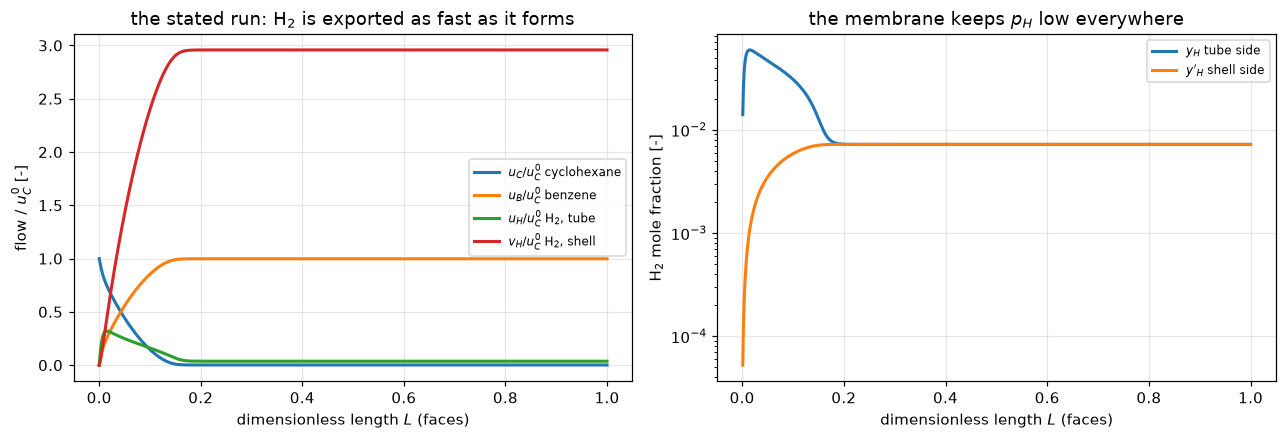

In [7]:
def headline(case=CASE, x_measured=X_MEASURED, n_z=800):
    """The stated run and its deviations from the measurement."""
    m = solve(case, UC0, VA0, n_z=n_z)
    X = m.conversion()
    return m, dict(X=X, dev=(X - x_measured) / x_measured,
                   unconv=1 - X, dev_unconv=((1 - X) - (1 - x_measured)) / (1 - x_measured),
                   dev_lo=(X - X_BAND[1]) / X_BAND[1], dev_hi=(X - X_BAND[0]) / X_BAND[0],
                   gain=X / X_EQ_STATED)


M_STATED, HL = headline()
X_MODEL = HL["X"]
print(f"stated run: u_C0 = {UC0:.2e} mol/s, v_A0 = {VA0:.2e} mol/s")
print(f"  measured conversion  {X_MEASURED:.3f}")
print(f"  model conversion     {X_MODEL:.4f}")
print(f"  deviation (model - measured)/measured = {HL['dev'] * 100:+.2f} %")
print("  ... but on the quantity that actually varies, the unconverted")
print(f"  fraction 1 - X: measured {1 - X_MEASURED:.4f}, model {HL['unconv']:.5f},")
print(f"  deviation {HL['dev_unconv'] * 100:+.0f} %. Both numbers describe the same solve;")
print("  see validation check 1 for which one carries information.")
print(f"  equilibrium without the membrane: {X_EQ_STATED} -> the membrane")
print(f"  multiplies the attainable conversion by {HL['gain']:.1f}")

wf = M_STATED.face_profiles()
Lf = M_STATED.z_f
yH_tube = wf[:, 1] / (1.0 + CASE.n_Ar + wf[:, 1])     # scaled tube total: 1 + n_Ar + u_H
yH_shell = wf[:, 2] / (VA0 / UC0 + wf[:, 2])
fig, ax = plt.subplots(1, 2, figsize=(11.8, 4.1))
ax[0].plot(Lf, wf[:, 0], lw=2, label="$u_C/u_C^0$ cyclohexane")
ax[0].plot(Lf, 1 - wf[:, 0], lw=2, label="$u_B/u_C^0$ benzene")
ax[0].plot(Lf, wf[:, 1], lw=2, label="$u_H/u_C^0$ H$_2$, tube")
ax[0].plot(Lf, wf[:, 2], lw=2, label="$v_H/u_C^0$ H$_2$, shell")
ax[0].set(xlabel="dimensionless length $L$ (faces)", ylabel="flow / $u_C^0$ [-]",
          title="the stated run: H$_2$ is exported as fast as it forms")
ax[0].legend(fontsize=8)
ax[1].semilogy(Lf[1:], yH_tube[1:], lw=2, label="$y_{H}$ tube side")
ax[1].semilogy(Lf[1:], yH_shell[1:], lw=2, label="$y'_{H}$ shell side")
ax[1].set(xlabel="dimensionless length $L$ (faces)", ylabel="H$_2$ mole fraction [-]",
          title="the membrane keeps $p_H$ low everywhere")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

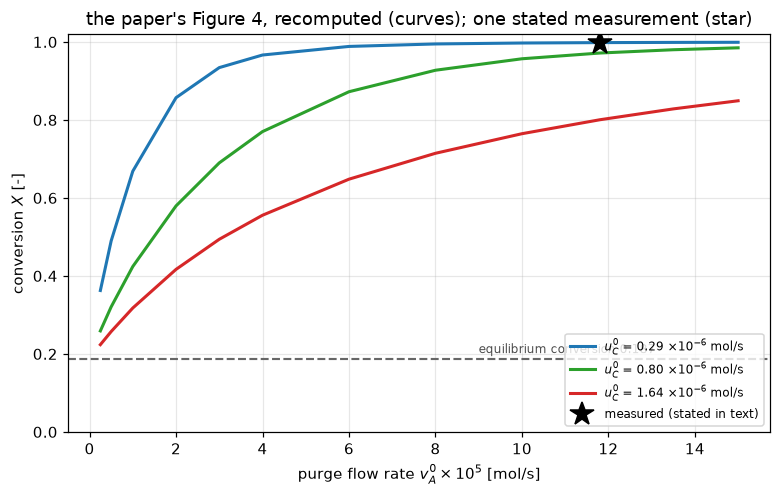

Every curve rises from the equilibrium conversion at zero purge toward
complete conversion: the membrane turns a thermodynamic ceiling into a
purge-rate knob. The curves reproduce the calculated curves of the paper's
Figure 4 (a reproduction; the figure's markers are not digitised).


In [8]:
VA0_SWEEP = np.array([0.25, 0.5, 1, 2, 3, 4, 6, 8, 10, 11.8, 13.5, 15]) * 1e-5
X_MAP = {uC0: np.array([solve(CASE, uC0, va).conversion() for va in VA0_SWEEP])
         for uC0 in UC0_CURVES}

fig, ax = plt.subplots(figsize=(7.2, 4.6))
for uC0, col in zip(UC0_CURVES, ("tab:blue", "tab:green", "tab:red")):
    ax.plot(VA0_SWEEP * 1e5, X_MAP[uC0], "-", lw=2, color=col,
            label=f"$u_C^0$ = {uC0 * 1e6:.2f} $\\times 10^{{-6}}$ mol/s")
ax.plot(VA0 * 1e5, X_MEASURED, "k*", ms=16, zorder=5, label="measured (stated in text)")
ax.axhline(X_EQ_STATED, color="0.4", ls="--", lw=1.4)
ax.text(9.0, X_EQ_STATED + 0.015, f"equilibrium conversion {X_EQ_STATED}", fontsize=8,
        color="0.3")
ax.set(xlabel="purge flow rate $v_A^0 \\times 10^5$ [mol/s]", ylabel="conversion $X$ [-]",
       ylim=(0, 1.02), title="the paper's Figure 4, recomputed (curves); one stated measurement (star)")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()
print("Every curve rises from the equilibrium conversion at zero purge toward")
print("complete conversion: the membrane turns a thermodynamic ceiling into a")
print("purge-rate knob. The curves reproduce the calculated curves of the paper's")
print("Figure 4 (a reproduction; the figure's markers are not digitised).")

## Validation

Seven checks. The stated measured conversion is the one comparison with a
measurement, and check 1 spends most of its length establishing how much that
comparison can actually resolve, which is less than the headline deviation
suggests. The rest are identities the paper pays for, limits, and
method-independence checks: reproduction, not validation.

In [9]:
SENS_VARIANTS = {
    "baseline": {},
    "alpha_H x 0.3": dict(alpha=0.3), "alpha_H x 10": dict(alpha=10.0),
    "k (== k*V_r) x 0.1": dict(k=0.1), "k (== k*V_r) x 10": dict(k=10.0),
    "K_p = the van 't Hoff value": dict(kp="vh"), "K_p x (K_p / K_vH)": dict(kp="vh_up"),
    "K_p / 3": dict(kp=1 / 3), "K_p x 10": dict(kp=10.0), "K_p / 10": dict(kp=0.1),
}


def sensitivity(case=CASE, vA0=VA0, labels=tuple(SENS_VARIANTS), K_vh=K_P_VH, n_z=800):
    """Conversion of the stated run under each perturbation in ``labels``."""
    out = {}
    for label in labels:
        v = SENS_VARIANTS[label]
        kp = v.get("kp", 1.0)
        if kp == "vh":
            K_p = K_vh                                # the van 't Hoff value
        elif kp == "vh_up":
            K_p = case.K_p ** 2 / K_vh                # up by the same factor
        else:
            K_p = case.K_p * kp
        c = replace(case, alpha_H=case.alpha_H * v.get("alpha", 1.0),
                    k_rate=case.k_rate * v.get("k", 1.0), K_p=K_p)
        out[label] = solve(c, UC0, vA0, n_z=n_z).conversion()
    return out


def spans(sens):
    """Largest change of X over the alpha_H and the k perturbations."""
    b = sens["baseline"]
    return (max(abs(sens[k] - b) for k in ("alpha_H x 0.3", "alpha_H x 10")),
            max(abs(sens[k] - b) for k in ("k (== k*V_r) x 0.1", "k (== k*V_r) x 10")))


SENS = sensitivity()
SENS_ALPHAH, SENS_K = spans(SENS)
lines = ["1. the measured conversion, and exactly how much it can resolve",
         f"   measured {X_MEASURED:.3f}, model {X_MODEL:.4f}, deviation {HL['dev'] * 100:+.2f} %",
         "   Nothing was fitted: kinetics and alpha_H are printed constants, K_p",
         "   comes from the printed equilibrium conversion, geometry from Fig. 1.",
         f"   |model - fast-permeation ceiling| below 1e-10 (here {abs(X_MODEL - CEIL_STATED):.1e})",
         "   At this operating point the model IS its own algebraic ceiling, a",
         "   closed-form function of (K_p, u_C0, v_A0, y_C0, P0) alone. 'Nothing",
         "   fitted' is true, but almost nothing could have made it fail. Perturbing",
         "   the model shows what the comparison can and cannot see:\n",
         f"   {'variant':<32}{'X_model':>10}{'dev vs measured':>17}"]
for label, Xs in SENS.items():
    lines.append(f"   {label:<32}{Xs:>10.5f}{(Xs - X_MEASURED) / X_MEASURED * 100:>+16.2f} %")
lines += [f"\n   alpha_H over a factor 33: X moves by below 1e-8 (here {SENS_ALPHAH:.1e})",
          f"   k (and hence V_r, and hence r_i) over a factor 100: X moves by below 1e-8 "
          f"(here {SENS_K:.1e})",
          "   So this comparison tests NEITHER the Langmuir-Hinshelwood kinetics NOR",
          "   the Sieverts permeance. It bounds K_p to roughly an order of magnitude,",
          "   and it does not distinguish the reconstruction from the van 't Hoff",
          "   value, which in fact agrees slightly BETTER with the measurement.",
          "   What it does establish is that the reactor reached its co-current",
          "   fast-permeation asymptote and that the model puts that asymptote in",
          "   the right place.\n",
          "   Two further honesty points on the same number:",
          "   (a) on the quantity that actually varies, the unconverted fraction:",
          f"       1 - X measured {1 - X_MEASURED:.4f}, model {HL['unconv']:.5f}, "
          f"deviation {HL['dev_unconv'] * 100:+.0f} %.",
          f"       The model under-predicts unconverted cyclohexane by "
          f"{abs(HL['dev_unconv']) * 100:.0f} %; that, not",
          f"       {HL['dev'] * 100:+.2f} %, is the honest measure of the disagreement.",
          f"   (b) '{X_MEASURED}' is three digits with no uncertainty, so X is only known to",
          f"       lie in [{X_BAND[0]:.4f}, {X_BAND[1]:.4f}] and the deviation only in "
          f"[{HL['dev_lo'] * 100:+.2f} %, {HL['dev_hi'] * 100:+.2f} %]."]
print("\n".join(lines))

1. the measured conversion, and exactly how much it can resolve
   measured 0.997, model 0.9983, deviation +0.13 %
   Nothing was fitted: kinetics and alpha_H are printed constants, K_p
   comes from the printed equilibrium conversion, geometry from Fig. 1.
   |model - fast-permeation ceiling| below 1e-10 (here 0.0e+00)
   At this operating point the model IS its own algebraic ceiling, a
   closed-form function of (K_p, u_C0, v_A0, y_C0, P0) alone. 'Nothing
   fitted' is true, but almost nothing could have made it fail. Perturbing
   the model shows what the comparison can and cannot see:

   variant                            X_model  dev vs measured
   baseline                           0.99834           +0.13 %
   alpha_H x 0.3                      0.99834           +0.13 %
   alpha_H x 10                       0.99834           +0.13 %
   k (== k*V_r) x 0.1                 0.99834           +0.13 %
   k (== k*V_r) x 10                  0.99834           +0.13 %
   K_p = the van 't 

In [10]:
print("2. alpha_H identity: Eq. 1 recomputed from its own printed inputs")
print(f"   printed {ALPHA_H:.2e}, recomputed {ALPHA_H_RECOMPUTED:.4e}, "
      f"deviation {(ALPHA_H_RECOMPUTED - ALPHA_H) / ALPHA_H * 100:+.2f} %")
print("   (shows Itoh used r_i = 8.5 mm in Eq. 1; consequential for nothing on")
print("    this page, see the note under Parameters)\n")

UC0_SLOW, VA0_TRICKLE = UC0 / 10, 1e-9      # a long residence time; any purge (alpha_H = 0)


def equilibrium_limit(case=CASE, uC0=UC0_SLOW):
    """alpha_H = 0: the tube alone, which must equilibrate at the stated x_eq."""
    return solve(replace(case, alpha_H=0.0), uC0, VA0_TRICKLE).conversion()


X_EQ_LIMIT = equilibrium_limit()
print("3. equilibrium limit: alpha_H = 0 recovers the stated equilibrium conversion")
print(f"   X(alpha_H=0, u_C0 = {UC0_SLOW:.2g} mol/s) = {X_EQ_LIMIT:.4f} vs stated {X_EQ_STATED}")
print("   (tests the reactor implementation against the closed-form K_p inversion;")
print("    K_p itself came from that statement, so this is a consistency check,")
print("    not independent evidence)")

2. alpha_H identity: Eq. 1 recomputed from its own printed inputs
   printed 4.47e-05, recomputed 4.4686e-05, deviation -0.03 %
   (shows Itoh used r_i = 8.5 mm in Eq. 1; consequential for nothing on
    this page, see the note under Parameters)

3. equilibrium limit: alpha_H = 0 recovers the stated equilibrium conversion
   X(alpha_H=0, u_C0 = 2.9e-08 mol/s) = 0.1870 vs stated 0.187
   (tests the reactor implementation against the closed-form K_p inversion;
    K_p itself came from that statement, so this is a consistency check,
    not independent evidence)


Check 4 compares the finite-volume solve with an independent stiff
initial-value integration (Radau) of the same equations. At the stated run
there is no grid error to show: the outlet sits on the fully equilibrated
fixed point, so the grid is tested mid-map, where the profiles are steep near
the inlet. Upwinding with the outflow outlet is backward Euler in $L$, so the
value in cell $i$ approximates the solution at the face $L_{i+1/2}$, and the
profile error is measured there, over every face and field.

In [11]:
def ivp_mid(rtol=1e-10, uC0=UC0_MID, vA0=VA0_MID):
    """The mid-map reference: X and the dense solution."""
    return conversion_ivp(CASE, uC0, vA0, rtol=rtol, dense=True)


def profile_error(m, sol, positions="faces"):
    """Largest |w_FV - w_IVP| over every field, and where it occurs (L).

    ``positions="faces"`` compares each cell with the reference at the face
    downstream of it; ``"centres"`` at the cell centre (a break-row handle).
    """
    if positions == "faces":
        L, w = m.z_f, m.face_profiles()
    else:
        L, w = m.z_c, m.w
    ref = sol.sol(L).T / m.uC0
    err = np.abs(w - ref).max(axis=1)
    return float(err.max()), float(L[np.argmax(err)])


def ladder(ns, ivp=None, outlet="outflow", positions="faces", read="face"):
    """Mid-map grid ladder: outlet-conversion and profile errors against the IVP."""
    X_ref, sol = ivp_mid() if ivp is None else ivp
    out = []
    for n in ns:
        m = solve(CASE, UC0_MID, VA0_MID, n_z=n, outlet=outlet)
        out.append((n, m.conversion(read) - X_ref, *profile_error(m, sol, positions)))
    return X_ref, out


def order(e_coarse, e_fine, ratio=2.0):
    """Observed order from two grids a factor ``ratio`` apart."""
    return np.log(abs(e_coarse) / abs(e_fine)) / np.log(ratio)


X_IVP = conversion_ivp(CASE, UC0, VA0)
M_100 = solve(CASE, UC0, VA0, n_z=100)
IVP_MID = ivp_mid()
X_IVP_MID, SOL_MID = IVP_MID
X_IVP_MID_TIGHT = conversion_ivp(CASE, UC0_MID, VA0_MID, rtol=1e-12)
NOISE_MID = max(abs(X_IVP_MID - X_IVP_MID_TIGHT), 1e-10)   # IVP tolerance, Newton tolerance
_, LAD = ladder((100, 200, 400, 800, 1600))
E = {n: (e, pe, pl) for n, e, pe, pl in LAD}
ORDER_X = order(E[800][0], E[1600][0])
ORDER_PROF = order(E[800][1], E[1600][1])
tab = ["4. two independent methods and grid convergence",
       f"   stiff-IVP reference (Radau, the paper's own RKG role): X = {X_IVP:.6f}",
       f"   FV at the stated run: X = {M_100.conversion():.6f} (n_z = 100), "
       f"{X_MODEL:.6f} (n_z = 800)",
       f"   |FV - IVP| below 1e-9 (here {abs(X_MODEL - X_IVP):.1e})",
       f"   |FV - ceiling| below 1e-10 (here {abs(X_MODEL - CEIL_STATED):.1e})",
       "   The outlet sits on the fully equilibrated fixed point (rate = 0,",
       "   permeation = 0), which IS the ceiling state: FV at any n_z, the IVP and",
       "   the algebraic ceiling agree to round-off.",
       f"   Mid-map (u_C0 = {UC0_MID:.2g}, v_A0 = {VA0_MID:.2g} mol/s; IVP X = {X_IVP_MID:.6f}):",
       f"   {'n_z':>6}{'X_fv - X_ivp':>14}{'ratio':>8}{'max profile err':>17}{'at L':>8}{'ratio':>8}"]
prev = None
for n, e, pe, pl in LAD:
    r1 = f"{prev[0] / e:.2f}" if prev else ""
    r2 = f"{prev[1] / pe:.2f}" if prev else ""
    tab.append(f"   {n:>6}{e:>+14.2e}{r1:>8}{pe:>17.2e}{pl:>8.4f}{r2:>8}")
    prev = (e, pe)
tab += [f"   observed order (800 -> 1600): outlet {ORDER_X:.3f}, profile {ORDER_PROF:.3f};"
        " the scheme is first order.",
        f"   finest outlet error / its noise floor: at least 1e3 (here {abs(E[1600][0]) / NOISE_MID:.1e})"]
print("\n".join(tab))

4. two independent methods and grid convergence
   stiff-IVP reference (Radau, the paper's own RKG role): X = 0.998344
   FV at the stated run: X = 0.998344 (n_z = 100), 0.998344 (n_z = 800)
   |FV - IVP| below 1e-9 (here 0.0e+00)
   |FV - ceiling| below 1e-10 (here 0.0e+00)
   The outlet sits on the fully equilibrated fixed point (rate = 0,
   permeation = 0), which IS the ceiling state: FV at any n_z, the IVP and
   the algebraic ceiling agree to round-off.
   Mid-map (u_C0 = 8e-07, v_A0 = 3e-05 mol/s; IVP X = 0.690030):
      n_z  X_fv - X_ivp   ratio  max profile err    at L   ratio
      100     -3.71e-04                 3.33e-02  0.0200        
      200     -1.81e-04    2.05         1.82e-02  0.0150    1.83
      400     -8.94e-05    2.03         9.78e-03  0.0175    1.86
      800     -4.43e-05    2.02         5.06e-03  0.0163    1.93
     1600     -2.21e-05    2.01         2.58e-03  0.0163    1.96
   observed order (800 -> 1600): outlet 1.006, profile 0.971; the scheme is first

In [12]:
print("5. conservation: the corrected Eq. 5 as an identity")
HBAL = abs(M_STATED.h_balance_error())
M_MID = solve(CASE, UC0_MID, VA0_MID)
HBAL_MID = abs(M_MID.h_balance_error())
print(f"   co-current, stated run: |u_H + v_H - 3(u_C0 - u_C)|/3(u_C0 - u_C) below 1e-12 "
      f"(here {HBAL:.1e})")
print(f"   co-current, mid-map (X = {M_MID.conversion():.3f}, far from equilibrium): below 1e-12 "
      f"(here {HBAL_MID:.1e})")
print("   The source conserves hydrogen exactly, and with face values the discrete")
print("   fluxes telescope, so this holds to round-off at any n_z, co-current and")
print("   counter-current alike (measured in 'What pymrm adds'). It checks the")
print("   implementation (the stoichiometry and the outlet read), not the grid.")
print("   Carbon closure is algebraic (u_B = u_C0 - u_C) and argon constant by")
print("   construction; the printed Eq. 5 (sign-flipped) would give v_H < 0.\n")


CEIL_EXCESS = max(X_MAP[uC0][i] - ceiling(CASE, uC0, va)
                  for uC0 in UC0_CURVES for i, va in enumerate(VA0_SWEEP))
print("6. the model bounded by its own ceiling everywhere on the map")
print(f"   max(X_model - X_ceiling) below 1e-9 (here {CEIL_EXCESS:.1e}): finite kinetics and")
print("   permeance never beat the bound (zero up to the solver tolerance).")

5. conservation: the corrected Eq. 5 as an identity
   co-current, stated run: |u_H + v_H - 3(u_C0 - u_C)|/3(u_C0 - u_C) below 1e-12 (here 7.4e-16)
   co-current, mid-map (X = 0.690, far from equilibrium): below 1e-12 (here 4.3e-16)
   The source conserves hydrogen exactly, and with face values the discrete
   fluxes telescope, so this holds to round-off at any n_z, co-current and
   counter-current alike (measured in 'What pymrm adds'). It checks the
   implementation (the stoichiometry and the outlet read), not the grid.
   Carbon closure is algebraic (u_B = u_C0 - u_C) and argon constant by
   construction; the printed Eq. 5 (sign-flipped) would give v_H < 0.

6. the model bounded by its own ceiling everywhere on the map
   max(X_model - X_ceiling) below 1e-9 (here 1.1e-16): finite kinetics and
   permeance never beat the bound (zero up to the solver tolerance).


## What pymrm adds

**The paper's own computation is an initial-value problem**: everything enters
at $L=0$, so Runge-Kutta marches it. Recasting it as a pymrm finite-volume
system with Newton solves reproduces it (check 4), which by itself adds only
robustness. The genuine addition is that the finite-volume form does not care
which end a stream enters: **counter-current purge is the same assembly** with
the shell channel given velocity $-1$, its inlet condition at $L=1$ and its
outflow at $L=0$, while a marching integrator would need shooting. The
comparison below is a *prediction*; Itoh's experiment was co-current only, and
no data exists to test it.

The co-current outlet sits on the algebraic ceiling at these purge rates and
returns the same number on every grid. The counter-current one does not: the
scheme is first order, and on the ladder below the observed order is still
rising toward 1 at 6400 cells. It is therefore run on a fine grid, with its
ladder and its hydrogen closure printed below, and quoted to two decimals.

Two things the comparison shows, both mechanistic rather than obvious:

- **At moderate purge, counter-current wins, and the margin is large.** Fresh
  argon meets the reactor *outlet*, where the last of the cyclohexane needs the
  deepest hydrogen removal; the co-current reactor instead delivers its most
  hydrogen-loaded purge exactly there, the pinch that produced the 0.72
  ceiling above.
- **At very low purge the order reverses.** With little argon, the
  counter-current shell carries its full hydrogen load past the reactor
  *inlet*, back-permeating hydrogen into the fresh feed where the tube-side
  $p_H$ is still low. Co-current avoids that because both streams start clean
  together.

The archival contribution of this page is the misprint resolution: **two**
printed statements, Eq. 5's sign and the $K_P$ expression, are wrong as
printed, and both corrections are derived from the paper's own statements. The
third value a reader might suspect, $v_A^0 = 11.8\times10^{-5}$ mol/s, is
printed correctly and is confirmed here rather than corrected.

In [13]:
VA0_CC = np.array([0.5, 1, 2, 3, 4, 5, 6, 7, 8]) * 1e-6
VA0_LO, VA0_HI = VA0_CC[0], VA0_CC[-1]
N_CC = 3200
N_LADDER = (400, 800, 1600, 3200, 6400)
CO_VS_CEIL = max(abs(solve(CASE, UC0, va, n_z=n).conversion() - ceiling(CASE, UC0, va))
                 for va in (VA0_LO, VA0_HI) for n in (400, N_CC))


def cc_ladder(case=CASE, ns=N_LADDER, vas=(VA0_LO, VA0_HI), flow="counter",
              outlet="outflow", read="face"):
    """Counter-current conversion and hydrogen closure on a grid ladder."""
    out = {}
    for va in vas:
        for n in ns:
            m = solve(case, UC0, va, n_z=n, flow=flow, outlet=outlet)
            out[(va, n)] = (m.conversion(read), m.h_balance_error(read))
    return out


CC_LADDER = cc_ladder()
CC_SHIFT = CC_LADDER[(VA0_LO, N_LADDER[-1])][0] - CC_LADDER[(VA0_LO, N_LADDER[0])][0]
_x = [CC_LADDER[(VA0_LO, n)][0] for n in N_LADDER]
ORDERS_CC = [order(_x[i] - _x[i + 1], _x[i + 1] - _x[i + 2]) for i in range(len(_x) - 2)]
ORDER_CC = ORDERS_CC[-1]
tab = [f"co-current over this purge range sits on the algebraic ceiling to below 1e-6 (here {CO_VS_CEIL:.1e}),",
       "so its numbers are the same at every n_z. The counter-current ones are not:",
       f"   {'v_A0':>10}{'n_z':>7}{'X_cc':>10}{'H closure':>12}"]
for (va, n), (X, hb) in CC_LADDER.items():
    tab.append(f"   {va:>10.1e}{n:>7d}{X:>10.4f}   (here {hb:+.1e})")
tab += [f"   Observed orders at v_A0 = {VA0_LO:.1e}, successive grid triples: "
        + ", ".join(f"{p:.3f}" for p in ORDERS_CC),
        "   rising toward the scheme's first order: this ladder is pre-asymptotic.",
        f"   The class default n_z = 400 is NOT converged here: X = "
        f"{CC_LADDER[(VA0_LO, 400)][0]:.4f} against {CC_LADDER[(VA0_LO, 6400)][0]:.4f} at n_z = 6400.",
        f"   The hydrogen closure holds to round-off on every grid: the outlet values",
        "   come from the faces, through which the operators transported them.",
        f"   The comparison below is run at n_z = {N_CC} and quoted to two decimals."]
print("\n".join(tab))

co-current over this purge range sits on the algebraic ceiling to below 1e-6 (here 4.5e-08),
so its numbers are the same at every n_z. The counter-current ones are not:
         v_A0    n_z      X_cc   H closure
      5.0e-07    400    0.2002   (here -7.4e-16)
      5.0e-07    800    0.1960   (here +8.9e-15)
      5.0e-07   1600    0.1933   (here +1.9e-15)
      5.0e-07   3200    0.1917   (here +1.6e-14)
      5.0e-07   6400    0.1908   (here -1.4e-15)
      8.0e-06    400    0.9338   (here +7.9e-16)
      8.0e-06    800    0.9341   (here -1.3e-15)
      8.0e-06   1600    0.9342   (here -4.8e-16)
      8.0e-06   3200    0.9342   (here -3.8e-15)
      8.0e-06   6400    0.9342   (here +9.5e-16)
   Observed orders at v_A0 = 5.0e-07, successive grid triples: 0.638, 0.785, 0.868
   rising toward the scheme's first order: this ladder is pre-asymptotic.
   The class default n_z = 400 is NOT converged here: X = 0.2002 against 0.1908 at n_z = 6400.
   The hydrogen closure holds to round-off on 

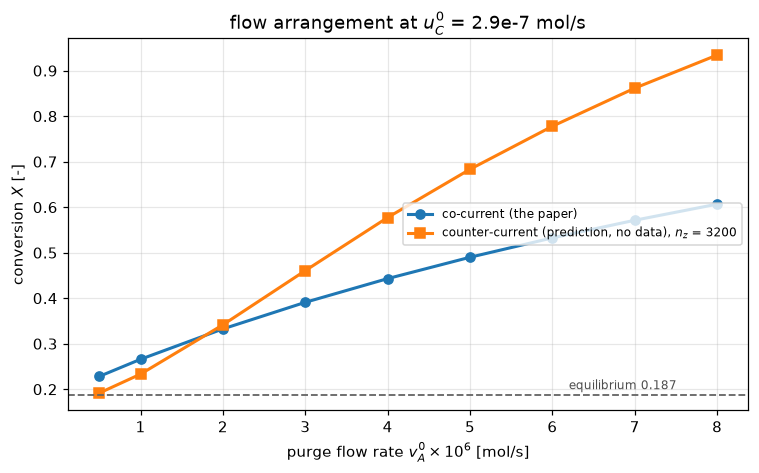

at v_A0 = 8e-06 mol/s: co-current X = 0.61, counter-current X = 0.93
at v_A0 = 5e-07 mol/s the order reverses: co 0.23 vs counter 0.19
worst counter-current hydrogen closure over the sweep at n_z = 3200: below 1e-12 (here 2.0e-14)


In [14]:
def arrangement_sweep(case=CASE, vas=VA0_CC, n_z=N_CC, cc_flow="counter"):
    """Co- and counter-current conversion over ``vas``, and the worst closure."""
    X_co, X_cc, hb = [], [], []
    for va in vas:
        X_co.append(solve(case, UC0, va, n_z=n_z).conversion())
        m = solve(case, UC0, va, n_z=n_z, flow=cc_flow)
        X_cc.append(m.conversion())
        hb.append(abs(m.h_balance_error()))
    return np.array(X_co), np.array(X_cc), max(hb)


X_CO, X_CC, HBAL_CC = arrangement_sweep()
fig, ax = plt.subplots(figsize=(7.0, 4.4))
ax.plot(VA0_CC * 1e6, X_CO, "o-", lw=2, color="tab:blue", label="co-current (the paper)")
ax.plot(VA0_CC * 1e6, X_CC, "s-", lw=2, color="tab:orange",
        label=f"counter-current (prediction, no data), $n_z$ = {N_CC}")
ax.axhline(X_EQ_STATED, color="0.4", ls="--", lw=1.2)
ax.text(6.2, X_EQ_STATED + 0.013, f"equilibrium {X_EQ_STATED}", fontsize=8, color="0.3")
ax.set(xlabel="purge flow rate $v_A^0 \\times 10^6$ [mol/s]", ylabel="conversion $X$ [-]",
       title=f"flow arrangement at $u_C^0$ = {UC0 * 1e7:.1f}e-7 mol/s")
ax.legend(fontsize=8, loc="center right")
fig.tight_layout(); plt.show()
print(f"at v_A0 = {VA0_HI:.0e} mol/s: co-current X = {X_CO[-1]:.2f}, "
      f"counter-current X = {X_CC[-1]:.2f}")
print(f"at v_A0 = {VA0_LO:.0e} mol/s the order reverses: co {X_CO[0]:.2f} vs counter {X_CC[0]:.2f}")
print(f"worst counter-current hydrogen closure over the sweep at n_z = {N_CC}: below 1e-12 "
      f"(here {HBAL_CC:.1e})")

### Where the counter-current solve stops

On 400 cells the counter-current solve does not converge above about
$9.4\times10^{-6}$ mol/s of purge, the last value continuation in $v_A^0$
reaches. That is a limit of the solver, not of the reactor. As the purge rises
toward it the outlet cyclohexane falls steeply (Eq. 7 is zero order far from
equilibrium, so cyclohexane can be used up inside the reactor), and past it the
Newton iterates have converted the cyclohexane completely (unconverted
fraction at the outlet below 1e-6) while the residual stays of order 100:
bounded Newton does not settle onto a state in which the cyclohexane runs out
inside the reactor. The square root of Eq. 1, whose slope is infinite at zero
hydrogen, is not the cause: with $\sqrt{y}$ replaced by $y/\sqrt{y + 10^{-8}}$,
smooth and linear at zero, continuation stops at the same purge and the cold
solve past it fails the same way. What the model predicts past the edge,
complete conversion inside the reactor, is what the iterates approach; no
independent route confirms it here, and the page reports no result from that
region. Every published counter-current point stays well below the edge: the
sweep ends at $8\times10^{-6}$ mol/s, and the cold solve below is at
$9.0\times10^{-6}$ mol/s.

In [15]:
VA0_SAFE, VA0_PAST = 9.0e-6, 1.2e-5     # mol/s: below the edge (about 5 %) and past it
SQRT_EPS = 1e-8                          # the smoothed square root of the check


def cc_edge(case=CASE, n_z=400):
    """The counter-current solve below and past the edge, with Eq. 1 as printed and
    with a smoothed square root: cold solves and continuation in the purge."""
    out = dict(unconverted=1 - solve(case, UC0, VA0_SAFE, n_z=n_z, flow="counter").conversion())
    for tag, c in (("", case), ("_smooth", replace(case, sqrt_eps=SQRT_EPS))):
        m = solve(c, UC0, VA0_SAFE, n_z=n_z, flow="counter")
        past = MembraneReactor(c, UC0, VA0_PAST, n_z=n_z, flow="counter")
        trace = MembraneReactor(c, UC0, VA0_SAFE, n_z=n_z, flow="counter")

        def residual(w, va, trace=trace):
            trace.vA0 = va
            return trace.residual(w)
        # Damping trials beyond the bounds give NaN square roots, which newton
        # rejects; continuation's secant predictions below the bounds are projected
        # onto them by newton, with a warning each time. Neither carries information.
        with np.errstate(invalid="ignore"), warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="newton: .* outside the bounds")
            r = newton(past.residual, past.initial_guess(), tol=1e-10, maxfev=100,
                       damping="monotone", bounds=past.BOUNDS)
            path = continuation(residual, m.w, np.linspace(VA0_SAFE, VA0_PAST, 13),
                                newton_kwargs=dict(tol=1e-10, damping="monotone",
                                                   bounds=trace.BOUNDS))
            g, _ = past.residual(r.x.reshape(past.shape))
        out.update({f"past_success{tag}": bool(r.success),
                    f"past_iterate_unconverted{tag}": float(r.x.reshape(past.shape)[-1, 0]),
                    f"past_residual{tag}": float(np.abs(g).max()),
                    f"path_reached{tag}": bool(path.success),
                    f"path_last{tag}": float(path.last_param)})
    return out


EDGE = cc_edge()
print(f"counter-current at v_A0 = {VA0_SAFE:.1e} mol/s (n_z = 400, cold start): "
      f"unconverted fraction at the outlet {EDGE['unconverted']:.2e}")
for tag, label in (("", "Eq. 1 as printed"), ("_smooth", f"sqrt(y) -> y/sqrt(y + {SQRT_EPS:g})")):
    print(f"{label}:")
    print(f"   continuation from {VA0_SAFE:.1e}: reached {VA0_PAST:.1e}: {EDGE['path_reached' + tag]}; "
          f"last converged (here {EDGE['path_last' + tag]:.2e}) mol/s")
    print(f"   cold start at {VA0_PAST:.1e}: converged {EDGE['past_success' + tag]}; not a result. "
          f"Its last iterate: unconverted below 1e-6 (here {EDGE['past_iterate_unconverted' + tag]:.1e}), "
          f"residual (here {EDGE['past_residual' + tag]:.0e})")

counter-current at v_A0 = 9.0e-06 mol/s (n_z = 400, cold start): unconverted fraction at the outlet 9.79e-03
Eq. 1 as printed:
   continuation from 9.0e-06: reached 1.2e-05: False; last converged (here 9.45e-06) mol/s
   cold start at 1.2e-05: converged False; not a result. Its last iterate: unconverted below 1e-6 (here 5.2e-12), residual (here 2e+02)
sqrt(y) -> y/sqrt(y + 1e-08):
   continuation from 9.0e-06: reached 1.2e-05: False; last converged (here 9.45e-06) mol/s
   cold start at 1.2e-05: converged False; not a result. Its last iterate: unconverted below 1e-6 (here 4.4e-09), residual (here 3e+06)


**What this page does not establish.** The comparison with measurement is a
*single* stated conversion, at an operating point where the model sits exactly
on its thermodynamic ceiling. Check 1 measures what that costs: varying
$\alpha_H$ over a factor 33 and $k V_r$ over a factor 100 moves the modelled
conversion by less than 1e-8, and $K_p$ can be divided by 3 or multiplied by
10 with the deviation staying between -0.19 % and +0.28 %. **So this page is not
experimental evidence for Itoh's Langmuir-Hinshelwood kinetics, nor for the
Sieverts permeance, and it does not select the reconstructed $K_p$ over the
van 't Hoff value**: the latter agrees marginally better. What the
measurement does establish is that the reactor reached its co-current
fast-permeation asymptote and that the model puts that asymptote in the right
place.

On the quantity that actually varies, the unconverted fraction $1-X$, the model
deviates by -45 %. That is the honest measure of the residual disagreement, and it is
consistent with $K_p$ being somewhat under-reconstructed, but the measurement
cannot pin it down, because $1-X$ is a 0.3 % effect on a conversion quoted to
three digits.

The low-purge region, where the kinetics and the permeation resistance
genuinely shape the curves, is checked only as a reproduction of the paper's
own calculated curves, not against the experimental markers of Figure 4, which
were not digitised. The $K_p$ used is a reconstruction from the paper's stated
equilibrium conversion; it is consistent with independent thermodynamic data at
the factor-1.6 level, but the printed expression it replaces remains unexplained,
most plausibly a garbled transcription from the kinetics source (Itoh et al.
1985, in Japanese), which was not available to check. The counter-current
comparison is a pure prediction, on a grid that is fine but not converged, with no data behind
it.

### Claims

Every number the page states is registered below with how it is checked
(`docs/claims-design.md`): a **value** against the committed baseline, a
**bound** at run time and in CI, an **exact** result by equality. Values set
by the stated run sit on an algebraic fixed point and are deterministic, so
their tolerances are tight; quantities zero by construction (closures, the
distance to the ceiling, the sensitivity spans) are bounds.

In [16]:
MIN_ITERS, MAX_ITERS = min(NEWTON_ITERS), max(NEWTON_ITERS)
print(f"{len(NEWTON_ITERS)} Newton solves on the page, each from the inlet state: "
      f"at least 2 (here {MIN_ITERS}) and at most 40 (here {MAX_ITERS}) iterations")
C = claims
# the data
C.value("conversion_measured", X_MEASURED, rtol=1e-9)
C.value("unconverted_measured", 1 - X_MEASURED, rtol=1e-9)
C.value("equilibrium_conversion_stated", X_EQ_STATED, rtol=1e-9)
C.value("v_A0_stated", VA0, rtol=1e-9, unit="mol/s")
C.value("u_C0_stated", UC0, rtol=1e-9, unit="mol/s")
# the parameters
C.value("k_473", CASE.k_rate, rtol=1e-6, unit="mol m-3 Pa-1 s-1")
C.value("K_B_473", CASE.K_B, rtol=1e-6, unit="1/Pa")
C.value("V_r", CASE.V_r, rtol=1e-6, unit="m3")
C.value("alphaH_recomputed_dev_frac", (ALPHA_H_RECOMPUTED - ALPHA_H) / ALPHA_H, rtol=1e-3)
C.value("alphaH_od_reading_dev_frac", (alpha_h(RI_OD, RO_OD) - ALPHA_H) / ALPHA_H, rtol=1e-3)
C.value("V_r_od_reading_change_frac", (RI / RI_OD) ** 2 - 1, rtol=1e-3)
# K_p and the printed line
C.value("Kp_473_reconstructed_Pa3", K_P, rtol=1e-6, unit="Pa3")
C.value("Kp_473_vanthoff_ratio", TH["ratio"], rtol=1e-3)
C.value("Kp_473_vanthoff_Pa3", K_P_VH, rtol=1e-3, unit="Pa3")
C.value("dH298_kJ_per_mol", TH["dH_kJ"], rtol=1e-4)
C.value("Kp_printed_473_Pa3", TH["printed"], rtol=1e-6, unit="Pa3")
C.value("Kp_printed_unconverted_eq", TH["printed_unconverted"], rtol=1e-2)
C.value("Kp_atm3_factor", TH["atm3_factor"], rtol=1e-6)
C.value("Kp_printed_atm3", TH["printed_atm3"], rtol=1e-6, unit="atm3")
C.value("Kp_needed_atm3", TH["needed_atm3"], rtol=1e-6, unit="atm3")
C.value("Kp_printed_vs_needed_decades", TH["orders"], rtol=1e-4)
C.value("Kp_prefactor_vanthoff_Pa3", TH["prefac_vh"], rtol=1e-3, unit="Pa3")
C.value("Kp_prefactor_ratio", TH["prefac_ratio"], rtol=1e-3)
C.value("Kp_slope_repair_K", TH["slope_repair"], rtol=1e-6, unit="K")
C.value("Kp_slope_vanthoff_K", TH["slope_vh"], rtol=1e-6, unit="K")
C.value("Kp_slope_gap_pct", TH["slope_gap_pct"], rtol=1e-3)
# the purge-rate exponent
C.value("ceiling_at_stated_run", CEIL_STATED, rtol=1e-6)
C.value("ceiling_at_1e-6_reading", CEIL_E6, rtol=1e-6)
C.value("ceiling_at_1e-6_reading_vanthoff", CEIL_E6_VH, rtol=1e-6)
C.value("Kp_needed_for_0.997_at_11.8e-6_ratio", KP_NEEDED / K_P, rtol=1e-4)
C.value("xeq_implied_by_Kp_needed", XEQ_NEEDED, rtol=1e-4)
# the headline comparison
C.value("conversion_model", X_MODEL, rtol=1e-6)
C.value("conversion_dev_frac", HL["dev"], rtol=1e-3)
C.value("unconverted_model", HL["unconv"], rtol=1e-4)
C.value("unconverted_dev_frac", HL["dev_unconv"], rtol=1e-4)
C.value("conversion_dev_band_lo_frac", HL["dev_lo"], rtol=1e-3)
C.value("conversion_dev_band_hi_frac", HL["dev_hi"], rtol=1e-3)
C.value("membrane_gain_over_equilibrium", HL["gain"], rtol=1e-4)
C.bound("stated_run_fv_vs_ceiling_absdiff", abs(X_MODEL - CEIL_STATED), max=1e-10,
        basis="tolerance", note="newton tol 1e-10 on the scaled flows")
C.bound("stated_run_fv_vs_ivp_absdiff", abs(X_MODEL - X_IVP), max=1e-9, basis="tolerance",
        note="newton tol 1e-10, Radau rtol 1e-10")
C.bound("stated_run_n100_vs_n800_absdiff", abs(M_100.conversion() - X_MODEL), max=1e-10,
        basis="tolerance", note="the outlet is an algebraic fixed point")
# check 1: the resolving power
C.bound("sens_alphaH_x0.3_to_x10_maxabs_dX", SENS_ALPHAH, max=1e-8, basis="tolerance",
        note="X is the ceiling, independent of alpha_H up to the newton tolerance")
C.bound("sens_kVr_x0.1_to_x10_maxabs_dX", SENS_K, max=1e-8, basis="tolerance",
        note="X is the ceiling, independent of k*V_r up to the newton tolerance")
C.value("sens_Kp_vanthoff_dev_frac", (SENS["K_p = the van 't Hoff value"] - X_MEASURED) / X_MEASURED,
        rtol=1e-3)
C.value("sens_Kp_div3_dev_frac", (SENS["K_p / 3"] - X_MEASURED) / X_MEASURED, rtol=1e-3)
C.value("sens_Kp_x10_dev_frac", (SENS["K_p x 10"] - X_MEASURED) / X_MEASURED, rtol=1e-3)
C.value("sens_Kp_div10_dev_frac", (SENS["K_p / 10"] - X_MEASURED) / X_MEASURED, rtol=1e-3)
# checks 3 to 6
C.value("equilibrium_limit_X", X_EQ_LIMIT, rtol=1e-6)
C.value("fv_vs_ivp_absdiff_midmap_nz800", abs(E[800][0]), rtol=1e-2)
C.value("fv_profile_maxerr_midmap_nz800", E[800][1], rtol=1e-2)
C.bound("fv_observed_order_midmap", ORDER_X, min=0.95, max=1.05, basis="theory",
        note="first-order upwind (backward Euler in L)")
C.bound("fv_profile_observed_order_midmap", ORDER_PROF, min=0.9, max=1.05, basis="theory",
        note="first-order upwind (backward Euler in L), approached from below")
C.bound("fv_finest_error_over_noise_midmap", abs(E[1600][0]) / NOISE_MID, min=1e3,
        basis="chosen", note="the order is fitted to error, not to noise")
C.bound("h_balance_rel_error_cocurrent", HBAL, max=1e-12, basis="identity")
C.bound("h_balance_rel_error_cocurrent_midmap", HBAL_MID, max=1e-12, basis="identity")
C.bound("ceiling_excess_over_map", CEIL_EXCESS, max=1e-9, basis="tolerance",
        note="X <= ceiling; the newton tolerance is the only slack")
C.bound("newton_iters_min", MIN_ITERS, min=2, basis="chosen",
        note="every solve on the page starts cold, from the inlet state")
C.bound("newton_iters_max", MAX_ITERS, max=40, basis="chosen",
        note="damped Newton from the inlet state converges in tens of iterations")
# what pymrm adds
C.bound("cocurrent_vs_ceiling_low_purge_absdiff", CO_VS_CEIL, max=1e-6, basis="chosen",
        note="co-current at these purge rates is on its ceiling to discretisation")
C.value("cc_X_0p5e-6_nz3200", CC_LADDER[(VA0_LO, N_CC)][0], rtol=1e-3)
C.value("cc_X_8e-6_nz3200", CC_LADDER[(VA0_HI, N_CC)][0], rtol=1e-3)
C.value("co_X_0p5e-6_nz3200", X_CO[0], rtol=1e-3)
C.value("co_X_8e-6_nz3200", X_CO[-1], rtol=1e-3)
C.value("cc_minus_co_8e-6", X_CC[-1] - X_CO[-1], rtol=1e-2)
C.value("cc_minus_co_0p5e-6", X_CC[0] - X_CO[0], rtol=1e-2)
C.value("cc_grid_shift_0p5e-6_nz400_to_nz6400", CC_SHIFT, rtol=1e-2)
C.value("cc_X_0p5e-6_nz400", CC_LADDER[(VA0_LO, 400)][0], rtol=1e-3)
C.value("cc_X_0p5e-6_nz6400", CC_LADDER[(VA0_LO, 6400)][0], rtol=1e-3)
C.bound("cc_observed_order", ORDER_CC, min=0.8, max=1.0, basis="chosen",
        note="first-order upwind, approached from below: pre-asymptotic on this ladder")
C.bound("h_balance_rel_error_countercurrent_nz3200", HBAL_CC, max=1e-12, basis="identity",
        note="face values: the discrete fluxes telescope")
C.value("cc_unconverted_9e-6_nz400", EDGE["unconverted"], rtol=1e-2)
for tag in ("", "_smooth"):
    sfx = "" if not tag else "_smoothed_sqrt"
    C.exact("cc_past_edge_converged" + sfx, EDGE["past_success" + tag])
    C.exact("cc_continuation_reaches_past_edge" + sfx, EDGE["path_reached" + tag])
    C.bound("cc_continuation_last_vA0" + sfx, EDGE["path_last" + tag], min=9.2e-6, max=9.7e-6,
            basis="chosen", unit="mol/s", note="where continuation stops on 400 cells")
    C.bound("cc_past_edge_iterate_unconverted" + sfx, EDGE["past_iterate_unconverted" + tag],
            max=1e-6, basis="chosen",
            note="the last iterate of a non-converged solve: what the solver approaches, not a result")
print(f"{len(C.metrics)} claims registered")

90 Newton solves on the page, each from the inlet state: at least 2 (here 8) and at most 40 (here 25) iterations
79 claims registered


### The defect-injection table

Each row breaks one thing on purpose, **re-runs** the computation behind its
claims with the defect in place, and hands the result to `claims.breaks`,
which records whether the claim's own check catches it. Every claim must be
failed by at least one row, and the last cell of the page raises otherwise.

In [17]:
BREAK = []


def brk(row, metric, value):
    """One injected defect: ``value`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, value)
    BREAK.append((row, metric, value, caught))


# the data file read one row off: every stated value is replaced by its neighbour
row = "data file read one row off"
S1 = stated(offset=1)
brk(row, "conversion_measured", S1["measured_conversion"])
brk(row, "unconverted_measured", 1 - S1["measured_conversion"])
brk(row, "equilibrium_conversion_stated", S1["equilibrium_conversion"])
brk(row, "u_C0_stated", S1["u_C0"])
brk("the purge read with the exponent -6", "v_A0_stated", VA0_E6)

# Arrhenius forms evaluated with T in Celsius; the OD reading of the radii
row = "Eq. 7 evaluated with T in degrees Celsius"
CASE_C = ItohCase.printed(T - 273.15, P0, Y_C0, K_P, alpha_H=ALPHA_H, r_i=RI, l_0=L0)
brk(row, "k_473", CASE_C.k_rate)
brk(row, "K_B_473", CASE_C.K_B)
row = "radii read as an outer diameter of 17.0 mm"
brk(row, "V_r", ItohCase.printed(T, P0, Y_C0, K_P, r_i=RI_OD, l_0=L0).V_r)
brk(row, "alphaH_recomputed_dev_frac", (alpha_h(RI_OD, RO_OD) - ALPHA_H) / ALPHA_H)
brk("the alpha_H identity with the radii swapped",
    "alphaH_od_reading_dev_frac", (alpha_h(RO_OD, RI_OD) - ALPHA_H) / ALPHA_H)
brk("V_r scaled with r_i instead of r_i squared", "V_r_od_reading_change_frac", RI / RI_OD - 1)

# the K_p chain
for row, kw in [("argon dilution ignored in K_p (y_C0 = 1)", dict(y_C0=1.0)),
                ("standard state 1 atm instead of 1 bar", dict(p_std=P0)),
                ("benzene formation enthalpy with the wrong sign", dict(dhf_benzene=-DHF_BENZENE)),
                ("printed K_P evaluated with T in degrees Celsius", dict(T=T - 273.15))]:
    th = thermo(**kw)
    for metric, key in [("Kp_473_reconstructed_Pa3", "K_p"), ("Kp_473_vanthoff_ratio", "ratio"),
                        ("Kp_473_vanthoff_Pa3", "K_vh"), ("dH298_kJ_per_mol", "dH_kJ"),
                        ("Kp_printed_473_Pa3", "printed"),
                        ("Kp_printed_unconverted_eq", "printed_unconverted"),
                        ("Kp_printed_atm3", "printed_atm3"), ("Kp_needed_atm3", "needed_atm3"),
                        ("Kp_printed_vs_needed_decades", "orders"),
                        ("Kp_prefactor_vanthoff_Pa3", "prefac_vh"),
                        ("Kp_prefactor_ratio", "prefac_ratio"),
                        ("Kp_slope_repair_K", "slope_repair"), ("Kp_slope_vanthoff_K", "slope_vh"),
                        ("Kp_slope_gap_pct", "slope_gap_pct")]:
        if th[key] != TH[key]:           # rows only where the defect enters the number
            brk(row, metric, th[key])
brk("1 atm taken as 1 bar in the units conversion", "Kp_atm3_factor", 1e5 ** 3)

# the ceiling and the purge-rate exponent, with the dilution ignored throughout
row = "argon dilution ignored (y_C0 = 1) in K_p and in the reactor"
TH1 = thermo(y_C0=1.0)
CASE1 = replace(CASE, y_C0=1.0, K_p=TH1["K_p"])
brk(row, "ceiling_at_stated_run", ceiling(CASE1, UC0, VA0))
brk(row, "ceiling_at_1e-6_reading", ceiling(CASE1, UC0, VA0_E6))
brk(row, "ceiling_at_1e-6_reading_vanthoff", ceiling(CASE1, UC0, VA0_E6, K_p=TH1["K_vh"]))
_kpn = kp_needed(CASE1)
brk(row, "Kp_needed_for_0.997_at_11.8e-6_ratio", _kpn / CASE1.K_p)
brk(row, "xeq_implied_by_Kp_needed", xeq_of_kp(_kpn, 1.0, P0))
_, HL1 = headline(CASE1)
for metric, key in [("conversion_model", "X"), ("conversion_dev_frac", "dev"),
                    ("unconverted_model", "unconv"), ("unconverted_dev_frac", "dev_unconv"),
                    ("conversion_dev_band_lo_frac", "dev_lo"),
                    ("conversion_dev_band_hi_frac", "dev_hi"),
                    ("membrane_gain_over_equilibrium", "gain")]:
    brk(row, metric, HL1[key])
SENS1 = sensitivity(CASE1, labels=("K_p = the van 't Hoff value", "K_p / 3", "K_p x 10", "K_p / 10"),
                    K_vh=TH1["K_vh"])
for metric, key in [("sens_Kp_vanthoff_dev_frac", "K_p = the van 't Hoff value"),
                    ("sens_Kp_div3_dev_frac", "K_p / 3"), ("sens_Kp_x10_dev_frac", "K_p x 10"),
                    ("sens_Kp_div10_dev_frac", "K_p / 10")]:
    brk(row, metric, (SENS1[key] - X_MEASURED) / X_MEASURED)
brk("argon dilution ignored in the reactor only (K_p as reconstructed)", "equilibrium_limit_X",
    equilibrium_limit(replace(CASE, y_C0=1.0)))

# a membrane a thousand times less permeable: off the ceiling
row = "permeance alpha_H / 1000"
CASE_A = replace(CASE, alpha_H=CASE.alpha_H / 1000)
X_A = solve(CASE_A, UC0, VA0, n_z=800).conversion()
brk(row, "stated_run_fv_vs_ceiling_absdiff", abs(X_A - CEIL_STATED))
brk(row, "stated_run_fv_vs_ivp_absdiff", abs(X_A - conversion_ivp(CASE_A, UC0, VA0)))
brk(row, "stated_run_n100_vs_n800_absdiff", abs(solve(CASE_A, UC0, VA0, n_z=100).conversion() - X_A))
SA = sensitivity(CASE_A, labels=("baseline", "alpha_H x 0.3", "alpha_H x 10"))
brk(row, "sens_alphaH_x0.3_to_x10_maxabs_dX",
    max(abs(SA[k] - SA["baseline"]) for k in ("alpha_H x 0.3", "alpha_H x 10")))
brk(row, "cocurrent_vs_ceiling_low_purge_absdiff",
    max(abs(solve(CASE_A, UC0, va).conversion() - ceiling(CASE, UC0, va)) for va in (VA0_LO, VA0_HI)))
EDGE_A = cc_edge(CASE_A)
brk(row, "cc_unconverted_9e-6_nz400", EDGE_A["unconverted"])
for tag in ("", "_smooth"):
    sfx = "" if not tag else "_smoothed_sqrt"
    brk(row, "cc_past_edge_converged" + sfx, EDGE_A["past_success" + tag])
    brk(row, "cc_continuation_reaches_past_edge" + sfx, EDGE_A["path_reached" + tag])
    brk(row, "cc_continuation_last_vA0" + sfx, EDGE_A["path_last" + tag])
    brk(row, "cc_past_edge_iterate_unconverted" + sfx, EDGE_A["past_iterate_unconverted" + tag])
row = "rate constant k / 1e4: kinetics-limited"
SK = sensitivity(replace(CASE, k_rate=CASE.k_rate * 1e-4),
                 labels=("baseline", "k (== k*V_r) x 0.1", "k (== k*V_r) x 10"))
brk(row, "sens_kVr_x0.1_to_x10_maxabs_dX",
    max(abs(SK[k] - SK["baseline"]) for k in ("k (== k*V_r) x 0.1", "k (== k*V_r) x 10")))

# the grid study
row = "zero-gradient outlet read at the last cell"
_, LZ = ladder((800,), ivp=IVP_MID, outlet="zero_gradient", read="cell")
brk(row, "fv_vs_ivp_absdiff_midmap_nz800", abs(LZ[0][1]))
row = "profile compared at cell centres instead of faces"
_, LC = ladder((800, 1600), ivp=IVP_MID, positions="centres")
brk(row, "fv_profile_maxerr_midmap_nz800", LC[0][2])
row = "IVP reference at rtol 1e-5"
IVP_LOOSE = ivp_mid(rtol=1e-5)
_, LL = ladder((800, 1600), ivp=IVP_LOOSE)
brk(row, "fv_observed_order_midmap", order(LL[0][1], LL[1][1]))
brk(row, "fv_finest_error_over_noise_midmap",
    abs(LL[1][1]) / max(abs(IVP_LOOSE[0] - X_IVP_MID_TIGHT), 1e-10))
row = "grid ladder 800, 1200 read as a factor 2"
_, L12 = ladder((1200,))
brk(row, "fv_profile_observed_order_midmap", order(E[800][1], L12[0][2]))
brk(row, "fv_observed_order_midmap", order(E[800][0], L12[0][1]))
_c = cc_ladder(ns=(1600, 3200, 4800), vas=(VA0_LO,))
_d = [_c[(VA0_LO, n)][0] for n in (1600, 3200, 4800)]
brk("counter-current ladder 1600, 3200, 4800 read as factors 2", "cc_observed_order",
    order(_d[0] - _d[1], _d[1] - _d[2]))

# hydrogen stoichiometry and the outlet read
row = "2.9 H2 per cyclohexane in the tube balance"
CASE_NU = replace(CASE, nu_H2=2.9)
brk(row, "h_balance_rel_error_cocurrent", abs(solve(CASE_NU, UC0, VA0, n_z=800).h_balance_error()))
brk(row, "h_balance_rel_error_cocurrent_midmap",
    abs(solve(CASE_NU, UC0_MID, VA0_MID).h_balance_error()))
row = "zero-gradient outlet, outlets read at the last cells"
_mz = solve(CASE, UC0, VA0_LO, n_z=N_CC, flow="counter", outlet="zero_gradient")
brk(row, "h_balance_rel_error_countercurrent_nz3200", abs(_mz.h_balance_error(read="cell")))

# the arrangement comparison, with the counter-current solve run co-current
row = "shell flow direction not reversed (counter-current run co-current)"
_c = cc_ladder(ns=(400, N_CC, 6400), vas=(VA0_LO, VA0_HI), flow="co")
brk(row, "cc_X_0p5e-6_nz3200", _c[(VA0_LO, N_CC)][0])
brk(row, "cc_X_8e-6_nz3200", _c[(VA0_HI, N_CC)][0])
brk(row, "cc_X_0p5e-6_nz400", _c[(VA0_LO, 400)][0])
brk(row, "cc_X_0p5e-6_nz6400", _c[(VA0_LO, 6400)][0])
brk(row, "cc_grid_shift_0p5e-6_nz400_to_nz6400", _c[(VA0_LO, 6400)][0] - _c[(VA0_LO, 400)][0])
brk(row, "cc_minus_co_8e-6", _c[(VA0_HI, N_CC)][0] - X_CO[-1])
brk(row, "cc_minus_co_0p5e-6", _c[(VA0_LO, N_CC)][0] - X_CO[0])
row = "co-current shell run counter-current"
brk(row, "co_X_0p5e-6_nz3200", X_CC[0])
brk(row, "co_X_8e-6_nz3200", X_CC[-1])
brk(row, "ceiling_excess_over_map",
    max(X_CC - np.array([ceiling(CASE, UC0, va) for va in VA0_CC])))

# the solver
_m = MembraneReactor(CASE, UC0, VA0, n_z=800)
with np.errstate(invalid="ignore"):
    _r = newton(_m.residual, _m.initial_guess(), tol=1e-15, maxfev=60, damping="monotone",
                bounds=_m.BOUNDS)
brk("newton tol 1e-15, below the round-off floor", "newton_iters_max", _r.nit)
brk("a warm start from the converged solution", "newton_iters_min",
    MembraneReactor(CASE, UC0, VA0, n_z=800).solve(w0=M_STATED.w).result.nit)

width = max(len(r) for r, *_ in BREAK)
out = [f"{'defect':<{width}}  {'claim':<42}{'broken':>13}  caught"]
for r, metric, value, caught in BREAK:
    v = repr(value)
    if isinstance(value, (float, np.floating)):
        # a round-off-level result differs between machines: shown as such
        v = f"(here {value:.1e})" if abs(value) < 1e-9 else f"{value:.4g}"
    out.append(f"{r:<{width}}  {metric:<42}{v:>13}  {'yes' if caught else 'no'}")
print("\n".join(out))

defect                                                              claim                                            broken  caught
data file read one row off                                          conversion_measured                             2.9e-07  yes
data file read one row off                                          unconverted_measured                                  1  yes
data file read one row off                                          equilibrium_conversion_stated                     0.197  yes
data file read one row off                                          u_C0_stated                                    0.000118  yes
the purge read with the exponent -6                                 v_A0_stated                                    1.18e-05  yes
Eq. 7 evaluated with T in degrees Celsius                           k_473                                     (here 1.2e-10)  yes
Eq. 7 evaluated with T in degrees Celsius                           K_B_473                  

## Reuse

**To adapt to your membrane reactor:** replace the rate expression in
`model.source` (and its equilibrium closure `kp_of_xeq`), the permeation law
(here Sieverts, $\propto \sqrt{p}$; a porous membrane would be linear in $p$
and non-selective, adding terms to *every* balance), and the constants of
`ItohCase`. More species widen the `"tube"` or `"shell"` domain of the
`BlockLayout` (`(n_z, n_tube)`, `(n_z, n_shell)`); each channel keeps its own
operators and boundary conditions, and only the source changes.

**The traps, in the order they will bite:**

- `NumJac` perturbs by at least an absolute 10⁻⁶: **scale unknowns to order
  one** or the Jacobian of any small-magnitude problem is noise.
- Rate expressions with equilibrium groups like $K_p p_C/p_H^3$ must be
  **regularised algebraically** (multiply through) before a Newton solver sees
  them; branch-based guards leave kinks that stall damped Newton.
- A convection-only outlet takes `{"outflow": True}`; a zero-gradient
  dictionary there makes the upwind operator extrapolate the exit face from
  two cells, and an outlet read from the last cell then misses what was
  transported (pitfall P8). Read outlets with `compute_boundary_values`.
- Near-complete conversion puts the solution on an equilibrium plateau:
  `newton(..., damping="monotone", bounds=...)`, with a lower bound where a
  square root or a denominator needs one.
- Boundary conditions use the **outward normal**: the same `{a, b, d}` dict
  means different physics at the two ends. Counter-current flow is the shell
  channel's own operator with velocity $-1$, its inlet dictionary at $L=1$ and
  `{"outflow": True}` at $L=0$ (`MembraneReactor(..., flow="counter")`).

**Related pages.** [`H1.1`](../H1.1-sieverts-permeation/) (the permeance of
the same tube, derived), [`H1.7`](../H1.7-solution-diffusion/) (membrane
transport, solution-diffusion), [`F2.3`](../F2.3-slurry-bubble-column-ft/)
(plug-flow reactor with printed-constant corrections established the same
way), [`D2.2`](../D2.2-van-welsenaere-froment-runaway/) (the same
convection-source finite-volume Newton assembly),
[`C2.1`](../C2.1-xu-froment-smr/) (equilibrium-limited kinetics against
experiment).

**Cite the source, not this page:** Itoh, N., *A membrane reactor using
palladium*, AIChE Journal **33**(9) 1576-1578 (1987),
[doi:10.1002/aic.690330921](https://doi.org/10.1002/aic.690330921).

In [18]:
# prose numbers: the Markdown cells of this notebook (README.md tags its own)
for lit, name in [
    # introduction and data
    ("18.7 %", "equilibrium_conversion_stated"), ("99.7 %", "conversion_measured"),
    ("0.997", "conversion_measured"), ("0.187", "equilibrium_conversion_stated"),
    ("2.90e-7", "u_C0_stated"), ("11.8e-5", "v_A0_stated"),
    # misprint 2 and the K_p section
    ("4.2e38", "Kp_printed_473_Pa3"), ("1e-25", "Kp_printed_unconverted_eq"),
    ("1.04e15", "Kp_atm3_factor"), ("4e23", "Kp_printed_atm3"), ("2.3e-4", "Kp_needed_atm3"),
    ("27", "Kp_printed_vs_needed_decades"), ("+206", "dH298_kJ_per_mol"),
    ("9.0e33", "Kp_prefactor_vanthoff_Pa3"), ("54", "Kp_prefactor_ratio"),
    ("-26484", "Kp_slope_repair_K"), ("7", "Kp_slope_gap_pct"),
    ("-24814", "Kp_slope_vanthoff_K"), ("0.72", "ceiling_at_1e-6_reading"),
    # parameters
    ("-0.03 %", "alphaH_recomputed_dev_frac"), ("2.653e-5", "k_473"), ("1.160e-4", "K_B_473"),
    ("2.357e11", "Kp_473_reconstructed_Pa3"), ("3.18e-5", "V_r"),
    ("-2.4 %", "alphaH_od_reading_dev_frac"), ("4.9 %", "V_r_od_reading_change_frac"),
    ("below 1e-8", "sens_kVr_x0.1_to_x10_maxabs_dX"),
    # what this page does not establish
    ("below 1e-8", "sens_alphaH_x0.3_to_x10_maxabs_dX"),
    ("-0.19 %", "sens_Kp_div3_dev_frac"), ("+0.28 %", "sens_Kp_x10_dev_frac"),
    ("-45 %", "unconverted_dev_frac"), ("1.6", "Kp_473_vanthoff_ratio"),
    ("0.3 %", "unconverted_measured"),
    # where the counter-current solve stops
    ("9.4e-6", "cc_continuation_last_vA0"), ("below 1e-6", "cc_past_edge_iterate_unconverted"),
    # where the counter-current solve stops
]:
    claims.says(lit, name)

In [19]:
# meta.yaml (validation, adds, agreement, caveats) and the models.yaml entry
for lit, name in [
    ("0.997", "conversion_measured"), ("2.90e-7", "u_C0_stated"), ("11.8e-5", "v_A0_stated"),
    ("0.9983", "conversion_model"), ("0.13 %", "conversion_dev_frac"),
    ("-45 %", "unconverted_dev_frac"), ("0.00166", "unconverted_model"),
    ("0.0030", "unconverted_measured"), ("below 1e-8", "sens_alphaH_x0.3_to_x10_maxabs_dX"),
    ("below 1e-8", "sens_kVr_x0.1_to_x10_maxabs_dX"), ("-0.03 %", "alphaH_recomputed_dev_frac"),
    ("-0.19 %", "sens_Kp_div3_dev_frac"), ("+0.28 %", "sens_Kp_x10_dev_frac"),
    ("at least 1e3", "fv_finest_error_over_noise_midmap"), ("99.7 %", "conversion_measured"),
    ("18.7 %", "equilibrium_conversion_stated"), ("1.58", "Kp_473_vanthoff_ratio"),
    ("2.36e11", "Kp_473_reconstructed_Pa3"), ("0.08 %", "conversion_dev_band_lo_frac"),
    ("0.19 %", "conversion_dev_band_hi_frac"), ("1.0", "fv_observed_order_midmap"),
    ("0.93", "cc_X_8e-6_nz3200"), ("0.61", "co_X_8e-6_nz3200"),
    ("0.19", "cc_X_0p5e-6_nz3200"), ("0.23", "co_X_0p5e-6_nz3200"),
    ("below 1e-12", "h_balance_rel_error_countercurrent_nz3200"),
    ("below 1e-12", "h_balance_rel_error_cocurrent"),
    ("0.716", "ceiling_at_1e-6_reading"), ("0.664", "ceiling_at_1e-6_reading_vanthoff"),
    ("338", "Kp_needed_for_0.997_at_11.8e-6_ratio"), ("0.734", "xeq_implied_by_Kp_needed"),
    ("4.4e-5", "fv_vs_ivp_absdiff_midmap_nz800"), ("9.4e-6", "cc_continuation_last_vA0"),
]:
    claims.says(lit, name)

In [20]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for H1.4:
  conversion_measured                             = 0.997            value  rtol 1e-09
  unconverted_measured                            = 0.003            value  rtol 1e-09
  equilibrium_conversion_stated                   = 0.187            value  rtol 1e-09
  v_A0_stated                                     = 0.000118         value  rtol 1e-09
  u_C0_stated                                     = 2.9e-07          value  rtol 1e-09
  k_473                                           = 2.6534e-05       value  rtol 1e-06
  K_B_473                                         = 0.00011599       value  rtol 1e-06
  V_r                                             = 3.1777e-05       value  rtol 1e-06
  alphaH_recomputed_dev_frac                      = -0.00032016      value  rtol 0.001
  alphaH_od_reading_dev_frac                      = -0.023571        value  rtol 0.001
  V_r_od_reading_change_frac                      = 0.048773         value  rtol 0.001
  Kp_473_reconstructed_Pa3